# Fingerprint Image Enhancement Using U-Net — Faster DirectML Training

**Configuration:** AMD Radeon GPU through DirectML, maximum 10 epochs, batch size 16, maximum 3,000 training batches per epoch.

**Important:** The current training split has about 52,888 images. Batch size 16 gives about 3,306 batches. Limiting training to 3,000 batches means approximately 48,000 shuffled training images are used in each epoch, not every training image. Set `MAX_TRAIN_BATCHES = None` to use all batches (about 3,306), if you prefer full passes.

This notebook uses a smaller U-Net base width (`base=16`) to reduce memory pressure because batch size 16 previously failed during backward on this DirectML setup. The run still must be tested on your machine; no code can guarantee speed or compatibility without running it on your hardware.


In [1]:
%pip install numpy pandas matplotlib opencv-python scikit-image scikit-learn tqdm


Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
import sys
import random
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tqdm.auto import tqdm
from skimage.metrics import (
    peak_signal_noise_ratio,
    structural_similarity
)

import torch
import torch.nn as nn
import torch.optim as optim
import torch_directml
from torch.utils.data import Dataset, DataLoader

DEVICE = torch_directml.device()

print("Python executable:", sys.executable)
print("PyTorch version:", torch.__version__)
print("DirectML device:", DEVICE)
print("All imports completed successfully!")

if not hasattr(torch, "from_numpy"):
    raise RuntimeError("PyTorch import did not initialize correctly.")


f:\COLLEGE\Semester 5\DIP\Case Study\Fingerprint-Image-Enhancement\.venv-gpu\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Python executable: f:\COLLEGE\Semester 5\DIP\Case Study\Fingerprint-Image-Enhancement\.venv-gpu\Scripts\python.exe
PyTorch version: 2.4.1+cpu
DirectML device: privateuseone:0
All imports completed successfully!


In [3]:
# Project directory
PROJECT_DIR = Path.cwd()
DATASET_DIR = PROJECT_DIR / "datasets"
OUTPUT_DIR = PROJECT_DIR / "outputs"
MODEL_DIR = OUTPUT_DIR / "models"
ENHANCED_DIR = OUTPUT_DIR / "enhanced_images"
for directory in [OUTPUT_DIR, MODEL_DIR, ENHANCED_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Training configuration
IMAGE_SIZE = 256
BATCH_SIZE = 16
NUM_EPOCHS = 10
MAX_TRAIN_BATCHES = 3000  # None = use every training batch
LEARNING_RATE = 1e-3
PATIENCE = 3
NUM_WORKERS = 2  # if Windows worker errors occur, set to 0
BASE_CHANNELS = 16  # lighter U-Net to reduce DirectML memory pressure

DEVICE = torch_directml.device()
print("Project directory:", PROJECT_DIR)
print("Dataset directory:", DATASET_DIR)
print("Training device:", DEVICE)
print("Batch size:", BATCH_SIZE)
print("Max training batches/epoch:", MAX_TRAIN_BATCHES)
print("Epochs:", NUM_EPOCHS)


Project directory: f:\COLLEGE\Semester 5\DIP\Case Study\Fingerprint-Image-Enhancement
Dataset directory: f:\COLLEGE\Semester 5\DIP\Case Study\Fingerprint-Image-Enhancement\datasets
Training device: privateuseone:0
Batch size: 16
Max training batches/epoch: 3000
Epochs: 10


In [4]:
def load_fingerprint(image_path, image_size=IMAGE_SIZE):
    """
    Load a fingerprint image in grayscale,
    resize it, and normalize pixel values to [0, 1].
    """
    image = cv2.imread(str(image_path), cv2.IMREAD_GRAYSCALE)

    if image is None:
        raise ValueError(f"Could not load image: {image_path}")

    image = cv2.resize(
        image,
        (image_size, image_size),
        interpolation=cv2.INTER_AREA
    )

    image = image.astype(np.float32) / 255.0

    return image


def denoise_fingerprint(image):
    """
    Apply median filtering to reduce impulse noise.
    Input and output are normalized grayscale images.
    """
    image_uint8 = np.clip(image * 255, 0, 255).astype(np.uint8)

    denoised = cv2.medianBlur(image_uint8, 3)

    return denoised.astype(np.float32) / 255.0


def enhance_contrast(image, clip_limit=2.0, tile_grid_size=(8, 8)):
    """
    Apply CLAHE to improve local contrast.
    """
    image_uint8 = np.clip(image * 255, 0, 255).astype(np.uint8)

    clahe = cv2.createCLAHE(
        clipLimit=clip_limit,
        tileGridSize=tile_grid_size
    )

    enhanced = clahe.apply(image_uint8)

    return enhanced.astype(np.float32) / 255.0

In [5]:
def image_to_tensor(image):
    """
    Convert a normalized grayscale image (H, W)
    into a float32 tensor (1, H, W).
    """
    image = np.asarray(image, dtype=np.float32)

    if image.ndim != 2:
        raise ValueError("Expected a 2D grayscale image.")

    if not np.isfinite(image).all():
        raise ValueError("Image contains NaN or infinite values.")

    image = np.clip(image, 0.0, 1.0)

    return torch.from_numpy(image).unsqueeze(0)

In [6]:
# Supported image formats
IMAGE_EXTENSIONS = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}

# Find images recursively inside datasets/
image_paths = sorted(
    p for p in DATASET_DIR.rglob("*")
    if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
)

print(f"Total fingerprint images found: {len(image_paths)}")
print("Dataset directory:", DATASET_DIR)

if not image_paths:
    raise FileNotFoundError(
        f"No fingerprint images found under {DATASET_DIR}. "
        "Check that your datasets/ folder is inside the project directory."
    )

print("First image:", image_paths[0].relative_to(DATASET_DIR))


Total fingerprint images found: 65830
Dataset directory: f:\COLLEGE\Semester 5\DIP\Case Study\Fingerprint-Image-Enhancement\datasets
First image: FVC2000\Dbs\Db1_a\100_1.tif


In [7]:
def degrade_fingerprint(clean_image):
    """
    Generate a synthetic degraded fingerprint from a normalized
    grayscale image in [0, 1].
    """
    image = np.clip(clean_image * 255, 0, 255).astype(np.uint8)

    # Random Gaussian blur
    if random.random() < 0.5:
        kernel_size = random.choice([3, 5])
        image = cv2.GaussianBlur(
            image, (kernel_size, kernel_size), 0
        )

    # Random Gaussian noise
    if random.random() < 0.8:
        noise = np.random.normal(0, random.uniform(3, 12), image.shape)
        image = np.clip(image.astype(np.float32) + noise, 0, 255)

    # Random contrast reduction
    if random.random() < 0.5:
        alpha = random.uniform(0.65, 0.95)
        beta = random.uniform(3, 20)
        image = np.clip(alpha * image + beta, 0, 255)

    return image.astype(np.float32) / 255.0

In [8]:
class FingerprintDataset(Dataset):
    def __init__(self, paths, image_size=IMAGE_SIZE, split="train"):
        self.paths = list(paths)
        self.image_size = image_size
        self.split = split

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, index):
        clean = load_fingerprint(
            self.paths[index], self.image_size
        )
        target = clean.copy()

        if self.split == "train":
            degraded = degrade_fingerprint(clean)
        else:
            # Deterministic degradation for validation and testing
            rng = np.random.default_rng(SEED + index)
            image = np.clip(clean * 255, 0, 255).astype(np.uint8)

            image = cv2.GaussianBlur(image, (3, 3), 0)
            noise = rng.normal(0, 5, image.shape)

            image = image.astype(np.float32)
            image = np.clip(0.8 * image + 10, 0, 255)
            degraded = np.clip(
                image + noise, 0, 255
            ).astype(np.float32) / 255.0

        return image_to_tensor(degraded), image_to_tensor(target)

In [9]:
from sklearn.model_selection import GroupShuffleSplit

def get_fingerprint_group(path):
    """
    HEURISTIC grouping only.

    This uses the relative parent folder plus the filename prefix before
    the first underscore. It prevents leakage only if that naming convention
    truly identifies a finger/subject within each dataset. Inspect examples
    from every dataset before treating the split as identity-independent.
    """
    path = Path(path)
    relative_parent = path.parent.relative_to(DATASET_DIR)
    identity_prefix = path.stem.split("_")[0]
    return str(relative_parent / identity_prefix)


groups = np.array([get_fingerprint_group(p) for p in image_paths])
indices = np.arange(len(image_paths))

print("Example path -> inferred group:")
for path in image_paths[:20]:
    print(f"{path.relative_to(DATASET_DIR)} -> {get_fingerprint_group(path)}")

print(
    "\nIMPORTANT: Verify the inferred group labels against the filename/folder "
    "conventions for FVC2000, FVC2002, FVC2004, and SOCOFing. "
    "The code cannot guarantee same-finger grouping if those conventions differ."
)

# 10% test split, grouped by the inferred group labels
split1 = GroupShuffleSplit(
    n_splits=1, test_size=0.10, random_state=SEED
)
trainval_idx, test_idx = next(
    split1.split(indices, groups=groups)
)

# Approximately 10% of the full dataset for validation
split2 = GroupShuffleSplit(
    n_splits=1, test_size=1/9, random_state=SEED
)
train_rel, val_rel = next(
    split2.split(trainval_idx, groups=groups[trainval_idx])
)

train_idx = trainval_idx[train_rel]
val_idx = trainval_idx[val_rel]

train_paths = [image_paths[i] for i in train_idx]
val_paths = [image_paths[i] for i in val_idx]
test_paths = [image_paths[i] for i in test_idx]

print("\nTraining images:", len(train_paths))
print("Validation images:", len(val_paths))
print("Testing images:", len(test_paths))

train_groups = set(groups[train_idx])
val_groups = set(groups[val_idx])
test_groups = set(groups[test_idx])

assert train_groups.isdisjoint(val_groups)
assert train_groups.isdisjoint(test_groups)
assert val_groups.isdisjoint(test_groups)

print("No overlap between inferred group labels.")


Example path -> inferred group:
FVC2000\Dbs\Db1_a\100_1.tif -> FVC2000\Dbs\Db1_a\100
FVC2000\Dbs\Db1_a\100_2.tif -> FVC2000\Dbs\Db1_a\100
FVC2000\Dbs\Db1_a\100_3.tif -> FVC2000\Dbs\Db1_a\100
FVC2000\Dbs\Db1_a\100_4.tif -> FVC2000\Dbs\Db1_a\100
FVC2000\Dbs\Db1_a\100_5.tif -> FVC2000\Dbs\Db1_a\100
FVC2000\Dbs\Db1_a\100_6.tif -> FVC2000\Dbs\Db1_a\100
FVC2000\Dbs\Db1_a\100_7.tif -> FVC2000\Dbs\Db1_a\100
FVC2000\Dbs\Db1_a\100_8.tif -> FVC2000\Dbs\Db1_a\100
FVC2000\Dbs\Db1_a\10_1.tif -> FVC2000\Dbs\Db1_a\10
FVC2000\Dbs\Db1_a\10_2.tif -> FVC2000\Dbs\Db1_a\10
FVC2000\Dbs\Db1_a\10_3.tif -> FVC2000\Dbs\Db1_a\10
FVC2000\Dbs\Db1_a\10_4.tif -> FVC2000\Dbs\Db1_a\10
FVC2000\Dbs\Db1_a\10_5.tif -> FVC2000\Dbs\Db1_a\10
FVC2000\Dbs\Db1_a\10_6.tif -> FVC2000\Dbs\Db1_a\10
FVC2000\Dbs\Db1_a\10_7.tif -> FVC2000\Dbs\Db1_a\10
FVC2000\Dbs\Db1_a\10_8.tif -> FVC2000\Dbs\Db1_a\10
FVC2000\Dbs\Db1_a\11_1.tif -> FVC2000\Dbs\Db1_a\11
FVC2000\Dbs\Db1_a\11_2.tif -> FVC2000\Dbs\Db1_a\11
FVC2000\Dbs\Db1_a\11_3.tif -> FVC2

In [10]:
train_dataset = FingerprintDataset(train_paths, split="train")
val_dataset = FingerprintDataset(val_paths, split="val")
test_dataset = FingerprintDataset(test_paths, split="test")

BATCH_SIZE = 16
NUM_WORKERS = 0

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=False
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=False
)

print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Testing images:", len(test_dataset))
print("Available training batches:", len(train_loader))
print(
    "Batches per epoch:",
    min(len(train_loader), MAX_TRAIN_BATCHES)
    if MAX_TRAIN_BATCHES is not None
    else len(train_loader)
)

Training images: 52883
Validation images: 6305
Testing images: 6642
Available training batches: 3306
Batches per epoch: 3000


In [11]:
inputs, targets = next(iter(train_loader))

print("Input batch shape:", inputs.shape)
print("Target batch shape:", targets.shape)
print("Input range:", inputs.min().item(), "to", inputs.max().item())
print("Target range:", targets.min().item(), "to", targets.max().item())

assert inputs.shape == targets.shape
assert inputs.ndim == 4
assert inputs.shape[1] == 1
assert torch.isfinite(inputs).all()
assert torch.isfinite(targets).all()

print("Batch verification passed.")

Input batch shape: torch.Size([16, 1, 256, 256])
Target batch shape: torch.Size([16, 1, 256, 256])
Input range: 0.0 to 1.0
Target range: 0.0 to 1.0
Batch verification passed.


In [12]:
class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),

            nn.Conv2d(out_channels, out_channels, 3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)


class UNet(nn.Module):
    def __init__(self, in_channels=1, out_channels=1, base=32):
        super().__init__()

        self.pool = nn.MaxPool2d(2)

        self.enc1 = DoubleConv(in_channels, base)
        self.enc2 = DoubleConv(base, base * 2)
        self.enc3 = DoubleConv(base * 2, base * 4)
        self.enc4 = DoubleConv(base * 4, base * 8)

        self.bottleneck = DoubleConv(base * 8, base * 16)

        self.up4 = nn.ConvTranspose2d(base * 16, base * 8, 2, 2)
        self.dec4 = DoubleConv(base * 16, base * 8)

        self.up3 = nn.ConvTranspose2d(base * 8, base * 4, 2, 2)
        self.dec3 = DoubleConv(base * 8, base * 4)

        self.up2 = nn.ConvTranspose2d(base * 4, base * 2, 2, 2)
        self.dec2 = DoubleConv(base * 4, base * 2)

        self.up1 = nn.ConvTranspose2d(base * 2, base, 2, 2)
        self.dec1 = DoubleConv(base * 2, base)

        self.output = nn.Conv2d(base, out_channels, 1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))

        b = self.bottleneck(self.pool(e4))

        d4 = self.dec4(torch.cat([self.up4(b), e4], dim=1))
        d3 = self.dec3(torch.cat([self.up3(d4), e3], dim=1))
        d2 = self.dec2(torch.cat([self.up2(d3), e2], dim=1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], dim=1))

        return torch.sigmoid(self.output(d1))

In [13]:
# Initialize the lighter U-Net on DirectML.
model = UNet(in_channels=1, out_channels=1, base=BASE_CHANNELS).to(DEVICE)
parameter_count = sum(p.numel() for p in model.parameters())
print(f"Parameters: {parameter_count:,}")
print("Training device:", DEVICE)
print("Model device:", next(model.parameters()).device)

# Forward-only smoke test with a real batch. No weights are updated here.
inputs, targets = next(iter(train_loader))
inputs = inputs.to(DEVICE)
targets = targets.to(DEVICE)
model.eval()
with torch.no_grad():
    outputs = model(inputs)
print("Input shape:", tuple(inputs.shape))
print("Output shape:", tuple(outputs.shape))
assert outputs.shape == targets.shape
assert torch.isfinite(outputs).all()
print("Forward-pass check passed.")


Parameters: 1,943,761
Training device: privateuseone:0
Model device: privateuseone:0
Input shape: (16, 1, 256, 256)
Output shape: (16, 1, 256, 256)
Forward-pass check passed.


In [14]:
# Small architecture/device check; no training or weight update.
sample = torch.randn(1, 1, IMAGE_SIZE, IMAGE_SIZE, device=DEVICE)
model.eval()
with torch.no_grad():
    prediction = model(sample)
assert prediction.shape == sample.shape
assert torch.isfinite(prediction).all()
print("Architecture check passed.")
print("Model device:", next(model.parameters()).device)


Architecture check passed.
Model device: privateuseone:0


In [15]:

from tqdm.auto import tqdm
import torch.nn as nn
import torch.optim as optim

setup_steps = [
    "Initializing loss function",
    "Initializing optimizer",
    "Setting checkpoint path"
]

with tqdm(
    total=len(setup_steps),
    desc="Model Setup",
    unit="step",
    dynamic_ncols=True
) as progress:

    criterion = nn.MSELoss()
    progress.update(1)
    progress.set_postfix(status="Loss function ready")

    optimizer = optim.Adam(
        model.parameters(),
        lr=LEARNING_RATE
    )
    progress.update(1)
    progress.set_postfix(status="Optimizer ready")

    BEST_MODEL_PATH = MODEL_DIR / "unet_fingerprint_best.pth"
    progress.update(1)
    progress.set_postfix(status="Checkpoint path ready")

print("\nLoss function: MSE")
print("Optimizer: Adam")
print("Learning rate:", LEARNING_RATE)
print("Checkpoint:", BEST_MODEL_PATH)
print("Setup completed successfully!")


Model Setup: 100%|██████████| 3/3 [00:01<00:00,  2.40step/s, status=Checkpoint path ready]


Loss function: MSE
Optimizer: Adam
Learning rate: 0.001
Checkpoint: f:\COLLEGE\Semester 5\DIP\Case Study\Fingerprint-Image-Enhancement\outputs\models\unet_fingerprint_best.pth
Setup completed successfully!


### Pilot run omitted

The previous notebook ran an additional 100-batch pilot before the full training, which duplicated training work. This version skips that pilot and proceeds directly to the capped 10-epoch loop after the device checks.


In [16]:
import time
from tqdm.auto import tqdm

BEST_MODEL_PATH = MODEL_DIR / "unet_fingerprint_best_directml.pth"
LAST_MODEL_PATH = MODEL_DIR / "unet_fingerprint_last_directml.pth"
HISTORY_PATH = OUTPUT_DIR / "training_history_directml.csv"
history = {"epoch": [], "train_loss": [], "val_loss": [], "epoch_seconds": []}
best_val_loss = float("inf")
epochs_without_improvement = 0

for epoch in range(NUM_EPOCHS):
    epoch_start = time.perf_counter()
    model.train()
    train_total_loss = 0.0
    train_samples = 0
    train_batches_done = 0
    batches_this_epoch = min(len(train_loader), MAX_TRAIN_BATCHES) if MAX_TRAIN_BATCHES is not None else len(train_loader)

    train_bar = tqdm(total=batches_this_epoch, desc=f"Epoch {epoch + 1}/{NUM_EPOCHS} [Train]", unit="batch", dynamic_ncols=True)
    try:
        for batch_idx, (inputs, targets) in enumerate(train_loader):
            if MAX_TRAIN_BATCHES is not None and batch_idx >= MAX_TRAIN_BATCHES:
                break
            inputs = inputs.to(DEVICE)
            targets = targets.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            predictions = model(inputs)
            loss = criterion(predictions, targets)
            loss.backward()
            optimizer.step()

            batch_n = inputs.size(0)
            train_total_loss += float(loss.detach().cpu().item()) * batch_n
            train_samples += batch_n
            train_batches_done += 1
            train_bar.update(1)
            train_bar.set_postfix(loss=f"{loss.item():.5f}", avg=f"{train_total_loss / max(train_samples, 1):.5f}")
    finally:
        train_bar.close()

    train_loss = train_total_loss / max(train_samples, 1)

    # Validation is run over the complete validation split each epoch.
    model.eval()
    val_total_loss = 0.0
    val_samples = 0
    with torch.no_grad():
        val_bar = tqdm(val_loader, desc=f"Epoch {epoch + 1}/{NUM_EPOCHS} [Val]", unit="batch", dynamic_ncols=True)
        for inputs, targets in val_bar:
            inputs = inputs.to(DEVICE)
            targets = targets.to(DEVICE)
            predictions = model(inputs)
            val_loss_batch = criterion(predictions, targets)
            batch_n = inputs.size(0)
            val_total_loss += float(val_loss_batch.detach().cpu().item()) * batch_n
            val_samples += batch_n
            val_bar.set_postfix(loss=f"{val_loss_batch.item():.5f}")
        val_bar.close()

    val_loss = val_total_loss / max(val_samples, 1)
    elapsed = time.perf_counter() - epoch_start
    history["epoch"].append(epoch + 1)
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["epoch_seconds"].append(elapsed)
    pd.DataFrame(history).to_csv(HISTORY_PATH, index=False)

    # Save a best checkpoint and a last checkpoint each epoch.
    checkpoint = {
        "epoch": epoch + 1,
        "model_state_dict": {k: v.detach().cpu() for k, v in model.state_dict().items()},
        "optimizer_state_dict": optimizer.state_dict(),
        "train_loss": train_loss,
        "val_loss": val_loss,
        "batch_size": BATCH_SIZE,
        "base_channels": BASE_CHANNELS,
        "image_size": IMAGE_SIZE,
    }
    torch.save(checkpoint, LAST_MODEL_PATH)

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        epochs_without_improvement = 0
        torch.save(checkpoint, BEST_MODEL_PATH)
        checkpoint_status = "Best checkpoint saved"
    else:
        epochs_without_improvement += 1
        checkpoint_status = f"No improvement ({epochs_without_improvement}/{PATIENCE})"

    print(f"\nEpoch {epoch + 1}/{NUM_EPOCHS} | train={train_loss:.6f} | val={val_loss:.6f} | batches={train_batches_done}/{len(train_loader)} | time={elapsed / 60:.1f} min | {checkpoint_status}")
    if epochs_without_improvement >= PATIENCE:
        print(f"Early stopping after epoch {epoch + 1}.")
        break

print("Training finished.")
print("Best validation loss:", best_val_loss)
print("Best checkpoint:", BEST_MODEL_PATH)
print("History CSV:", HISTORY_PATH)


Epoch 1/10 [Train]:   0%|          | 0/3000 [00:00<?, ?batch/s]f:\COLLEGE\Semester 5\DIP\Case Study\Fingerprint-Image-Enhancement\.venv-gpu\Lib\site-packages\torch\optim\adam.py:534: UserWarning: The operator 'aten::lerp.Scalar_out' is not currently supported on the DML backend and will fall back to run on the CPU. This may have performance implications. (Triggered internally at C:\__w\1\s\pytorch-directml-plugin\torch_directml\csrc\dml\dml_cpu_fallback.cpp:17.)
  torch._foreach_lerp_(device_exp_avgs, device_grads, 1 - beta1)
Epoch 1/10 [Val]: 100%|██████████| 395/395 [03:50<00:00,  1.71batch/s, loss=0.00145]



Epoch 1/10 | train=0.003792 | val=0.002556 | batches=3000/3306 | time=92.2 min | Best checkpoint saved


Epoch 2/10 [Val]: 100%|██████████| 395/395 [02:39<00:00,  2.48batch/s, loss=0.00151]



Epoch 2/10 | train=0.001392 | val=0.005025 | batches=3000/3306 | time=83.4 min | No improvement (1/3)


Epoch 3/10 [Val]: 100%|██████████| 395/395 [02:42<00:00,  2.42batch/s, loss=0.00059]


...


Epoch 7/10 | train=0.000601 | val=0.001674 | batches=3000/3306 | time=92.1 min | No improvement (1/3)


Epoch 8/10 [Val]: 100%|██████████| 395/395 [02:53<00:00,  2.28batch/s, loss=0.00106]



Epoch 8/10 | train=0.000557 | val=0.002718 | batches=3000/3306 | time=87.6 min | No improvement (2/3)


Epoch 9/10 [Val]: 100%|██████████| 395/395 [03:11<00:00,  2.07batch/s, loss=0.00058]



Epoch 9/10 | train=0.000552 | val=0.001396 | batches=3000/3306 | time=88.4 min | No improvement (3/3)
Early stopping after epoch 9.
Training finished.
Best validation loss: 0.001390565997934963
Best checkpoint: f:\COLLEGE\Semester 5\DIP\Case Study\Fingerprint-Image-Enhancement\outputs\models\unet_fingerprint_best_directml.pth
History CSV: f:\COLLEGE\Semester 5\DIP\Case Study\Fingerprint-Image-Enhancement\outputs\training_history_directml.csv


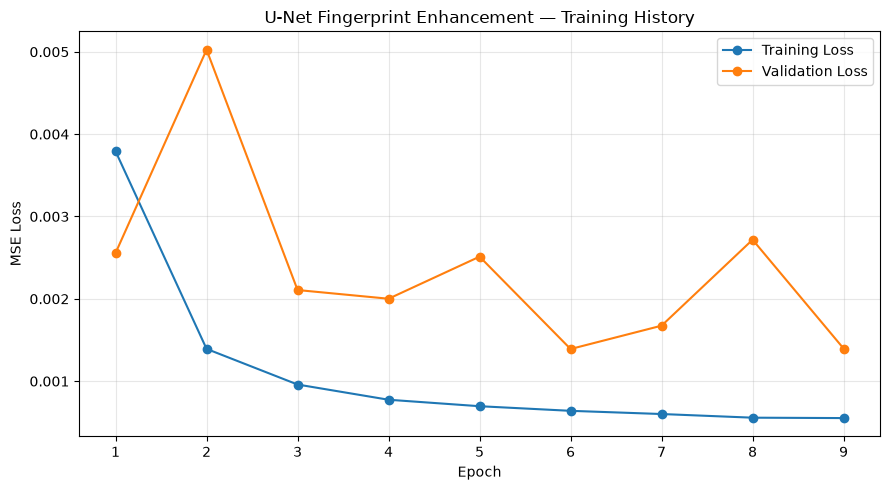

In [17]:

plt.figure(figsize=(9, 5))

plt.plot(
    range(1, len(history["train_loss"]) + 1),
    history["train_loss"],
    marker="o",
    label="Training Loss"
)
plt.plot(
    range(1, len(history["val_loss"]) + 1),
    history["val_loss"],
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("U-Net Fingerprint Enhancement — Training History")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [19]:
# Load the trusted checkpoint on CPU, then move the model to DirectML.

checkpoint = torch.load(
    BEST_MODEL_PATH,
    map_location="cpu",
    weights_only=False
)

model = UNet(
    in_channels=1,
    out_channels=1,
    base=checkpoint.get("base_channels", BASE_CHANNELS)
)

model.load_state_dict(checkpoint["model_state_dict"])
model = model.to(DEVICE)
model.eval()

print("Best checkpoint loaded successfully.")
print("Best epoch:", checkpoint.get("epoch", "Unknown"))
print("Best validation loss:", checkpoint.get("val_loss", "Unknown"))
print("Model device:", next(model.parameters()).device)

Best checkpoint loaded successfully.
Best epoch: 6
Best validation loss: 0.001390565997934963
Model device: privateuseone:0


In [20]:
# Quantitative evaluation on the entire held-out test set.
# Metrics are computed per image on normalized grayscale images in [0, 1].
model.eval()

all_rmse = []
all_psnr = []
all_ssim = []

with torch.no_grad():
    for inputs, targets in tqdm(test_loader, desc="Evaluating test set"):
        inputs = inputs.to(DEVICE)
        targets = targets.to(DEVICE)

        predictions = model(inputs)

        predictions = predictions.detach().cpu().numpy()[:, 0]
        targets = targets.detach().cpu().numpy()[:, 0]

        for pred, target in zip(predictions, targets):
            pred = np.clip(pred, 0.0, 1.0)
            target = np.clip(target, 0.0, 1.0)

            mse = float(np.mean((pred - target) ** 2))
            rmse = float(np.sqrt(mse))
            psnr = float(peak_signal_noise_ratio(
                target, pred, data_range=1.0
            ))
            ssim = float(structural_similarity(
                target, pred, data_range=1.0
            ))

            all_rmse.append(rmse)
            all_psnr.append(psnr)
            all_ssim.append(ssim)

if not all_rmse:
    raise RuntimeError("Test evaluation produced no results. Check test_loader.")

test_results = {
    "num_test_images": len(all_rmse),
    "mean_rmse": float(np.mean(all_rmse)),
    "mean_psnr_db": float(np.mean(all_psnr)),
    "mean_ssim": float(np.mean(all_ssim)),
}

print("\nFull Test Set Results")
print("---------------------")
print(f"Images evaluated: {test_results['num_test_images']}")
print(f"Mean RMSE: {test_results['mean_rmse']:.6f} (lower is better)")
print(f"Mean PSNR: {test_results['mean_psnr_db']:.4f} dB (higher is better)")
print(f"Mean SSIM: {test_results['mean_ssim']:.6f} (higher is better)")
print(
    "\nNote: these scores measure reconstruction against clean references "
    "for the notebook's synthetic degradation process. They do not by "
    "themselves establish performance on naturally degraded fingerprints."
)


Evaluating test set: 100%|██████████| 416/416 [04:54<00:00,  1.41it/s]


Full Test Set Results
---------------------
Images evaluated: 6642
Mean RMSE: 0.031313 (lower is better)
Mean PSNR: 30.7577 dB (higher is better)
Mean SSIM: 0.947728 (higher is better)

Note: these scores measure reconstruction against clean references for the notebook's synthetic degradation process. They do not by themselves establish performance on naturally degraded fingerprints.


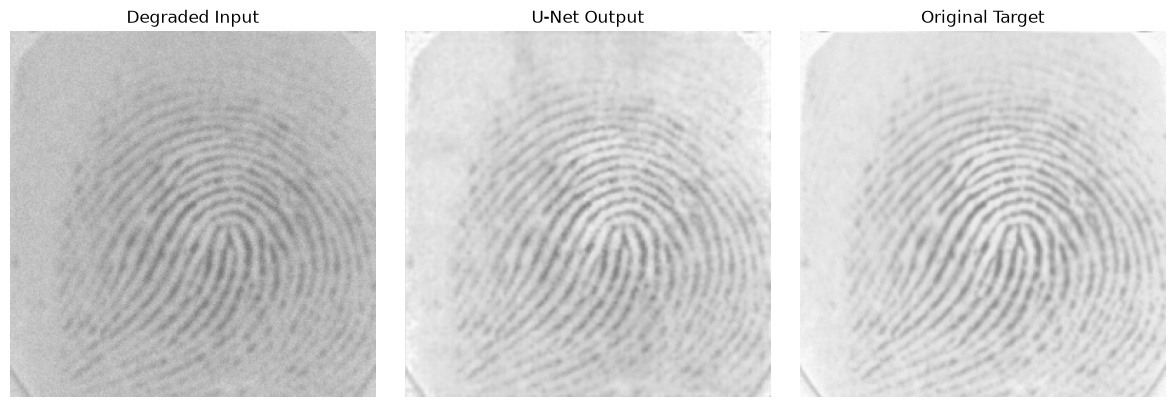

In [21]:
# Visualize one held-out test example.
test_dataset = FingerprintDataset(test_paths, split="test")
degraded_tensor, target_tensor = test_dataset[0]

model.eval()
with torch.no_grad():
    enhanced_tensor = model(
        degraded_tensor.unsqueeze(0).to(DEVICE)
    ).detach().cpu().squeeze(0)

degraded = degraded_tensor.squeeze().numpy()
original = target_tensor.squeeze().numpy()
enhanced = enhanced_tensor.squeeze().numpy()

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

axes[0].imshow(degraded, cmap="gray", vmin=0, vmax=1)
axes[0].set_title("Degraded Input")

axes[1].imshow(enhanced, cmap="gray", vmin=0, vmax=1)
axes[1].set_title("U-Net Output")

axes[2].imshow(original, cmap="gray", vmin=0, vmax=1)
axes[2].set_title("Original Target")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


In [22]:

from pathlib import Path
import cv2
import numpy as np
import torch
from tqdm.auto import tqdm

# Save predictions in the existing project output folder
PREDICTION_DIR = PROJECT_DIR / "outputs" / "enhanced_images"
PREDICTION_DIR.mkdir(parents=True, exist_ok=True)

model.eval()
saved_count = 0

with torch.no_grad():
    for inputs, targets in tqdm(
        test_loader,
        desc="Generating U-Net predictions"
    ):
        inputs = inputs.to(DEVICE)

        # Actual U-Net inference using trained weights
        predictions = model(inputs).detach().cpu().numpy()[:, 0]

        for prediction in predictions:
            image = np.clip(
                prediction * 255.0, 0, 255
            ).astype(np.uint8)

            output_path = PREDICTION_DIR / (
                f"fingerprint_{saved_count:05d}.png"
            )

            if cv2.imwrite(str(output_path), image):
                saved_count += 1

print(f"Saved {saved_count} U-Net predictions.")
print("Output folder:", PREDICTION_DIR.resolve())


Generating U-Net predictions: 100%|██████████| 416/416 [03:20<00:00,  2.07it/s]

Saved 6642 U-Net predictions.
Output folder: F:\COLLEGE\Semester 5\DIP\Case Study\Fingerprint-Image-Enhancement\outputs\enhanced_images


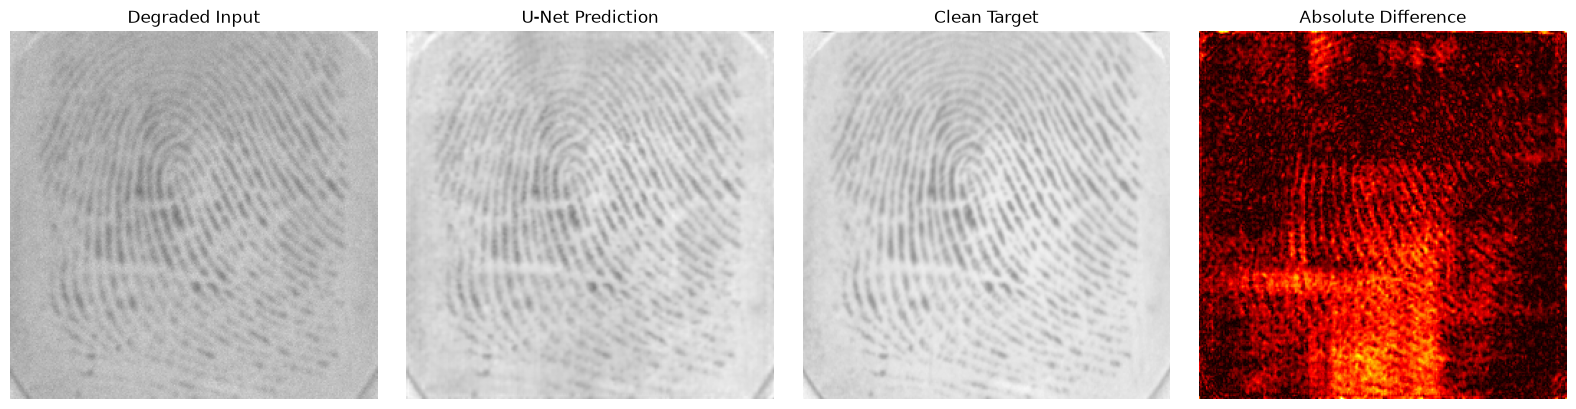

Mean absolute error: 0.029064242


In [24]:

import matplotlib.pyplot as plt
import torch
import numpy as np

model.eval()

# Get one batch from the test dataset
batch_index = 5
inputs, targets = list(test_loader)[batch_index]

# Run the trained U-Net
with torch.no_grad():
    predictions = model(inputs.to(DEVICE)).cpu()

# Display the first sample
degraded = inputs[0, 0].cpu().numpy()
predicted = predictions[0, 0].numpy()
target = targets[0, 0].cpu().numpy()

difference = np.abs(predicted - target)

fig, axes = plt.subplots(1, 4, figsize=(16, 4))

axes[0].imshow(degraded, cmap="gray", vmin=0, vmax=1)
axes[0].set_title("Degraded Input")

axes[1].imshow(predicted, cmap="gray", vmin=0, vmax=1)
axes[1].set_title("U-Net Prediction")

axes[2].imshow(target, cmap="gray", vmin=0, vmax=1)
axes[2].set_title("Clean Target")

axes[3].imshow(difference, cmap="hot")
axes[3].set_title("Absolute Difference")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Mean absolute error:", difference.mean())


In [25]:

import numpy as np
import torch
from skimage.metrics import (
    peak_signal_noise_ratio,
    structural_similarity
)
from math import sqrt

model.eval()

mae_values = []
rmse_values = []
psnr_values = []
ssim_values = []

with torch.no_grad():
    for batch_idx, (inputs, targets) in enumerate(test_loader):
        if batch_idx >= 10:
            break

        predictions = model(inputs.to(DEVICE)).cpu().numpy()[:, 0]
        targets_np = targets.cpu().numpy()[:, 0]

        for pred, target in zip(predictions, targets_np):
            pred = np.clip(pred, 0, 1)
            target = np.clip(target, 0, 1)

            diff = pred - target

            mae_values.append(np.mean(np.abs(diff)))
            rmse_values.append(sqrt(np.mean(diff ** 2)))
            psnr_values.append(
                peak_signal_noise_ratio(target, pred, data_range=1.0)
            )
            ssim_values.append(
                structural_similarity(target, pred, data_range=1.0)
            )

print("Images evaluated:", len(mae_values))
print(f"Mean MAE:  {np.mean(mae_values):.6f}")
print(f"Mean RMSE: {np.mean(rmse_values):.6f}")
print(f"Mean PSNR: {np.mean(psnr_values):.4f} dB")
print(f"Mean SSIM: {np.mean(ssim_values):.6f}")


Images evaluated: 160
Mean MAE:  0.035064
Mean RMSE: 0.043045
Mean PSNR: 27.9224 dB
Mean SSIM: 0.927344


In [26]:

import cv2
import numpy as np
import torch
from math import sqrt
from skimage.metrics import (
    peak_signal_noise_ratio,
    structural_similarity
)

model.eval()

# Store both methods' results on the same samples
results = {
    "U-Net": {"mae": [], "rmse": [], "psnr": [], "ssim": []},
    "U-Net + CLAHE": {"mae": [], "rmse": [], "psnr": [], "ssim": []}
}

clahe = cv2.createCLAHE(
    clipLimit=2.0,
    tileGridSize=(8, 8)
)

with torch.no_grad():
    for batch_idx, (inputs, targets) in enumerate(test_loader):
        if batch_idx >= 10:
            break

        predictions = model(inputs.to(DEVICE)).cpu().numpy()[:, 0]
        targets_np = targets.cpu().numpy()[:, 0]

        for pred, target in zip(predictions, targets_np):
            pred = np.clip(pred, 0, 1)
            target = np.clip(target, 0, 1)

            # Apply CLAHE to the U-Net prediction
            pred_uint8 = (pred * 255).round().astype(np.uint8)
            clahe_uint8 = clahe.apply(pred_uint8)
            clahe_pred = clahe_uint8.astype(np.float32) / 255.0

            for method, output in [
                ("U-Net", pred),
                ("U-Net + CLAHE", clahe_pred)
            ]:
                diff = output - target

                results[method]["mae"].append(
                    np.mean(np.abs(diff))
                )
                results[method]["rmse"].append(
                    sqrt(np.mean(diff ** 2))
                )
                results[method]["psnr"].append(
                    peak_signal_noise_ratio(
                        target, output, data_range=1.0
                    )
                )
                results[method]["ssim"].append(
                    structural_similarity(
                        target, output, data_range=1.0
                    )
                )

print("Evaluation completed on the same test batches.\n")

for method, metrics in results.items():
    print(method)
    for metric, values in metrics.items():
        print(f"  Mean {metric.upper()}: {np.mean(values):.6f}")
    print()


Evaluation completed on the same test batches.

U-Net
  Mean MAE: 0.035064
  Mean RMSE: 0.043045
  Mean PSNR: 27.922371
  Mean SSIM: 0.927344

U-Net + CLAHE
  Mean MAE: 0.105563
  Mean RMSE: 0.128589
  Mean PSNR: 18.036170
  Mean SSIM: 0.729609

